**Tópicos Selectos en Aprendizaje Maquinal - TP N°1: Algoritmos para Reconocimiento de Patrones**

**Estanislao Claucich**

### Ejercicio 9: Redes neuronales dinámicas

1. Implemente la arquitectura y entrenamiento Hebbiano para una red recurrente de Hopfield con los patrones que se muestran en la Figura 5.

2. Utilice la red de Hopfield como memoria asociativa para los patrones de la Figura 6.

3. Agregue diferentes cantidades de ruido a los patrones de la Figura 6 y utilice estos ejemplos ruidosos para acceder a las memorias fundamentales almacenadas como en el ejercicio anterior. Para simular cantidades controladas de ruido se sugiere invertir (blanco a negro y viceversa) cada pixel del dígito con probabilidades 0.1, 0.2 y 0.5.

In [15]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

rng = np.random.default_rng(42)

La red de Hopfield es una red recurrente de $N$ neuronas binarias $s_i\in\{-1,+1\}$ completamente conectadas, con pesos simétricos $w_{ij}=w_{ji}$ y sin autoconexiones ($w_{ii}=0$). Acá cada neurona es un píxel de la imagen (negro $=+1$, blanco $=-1$). El estado $\mathbf{s}$ evoluciona solo y el resultado es el estado al que llega.

- **Dinámica:** Con el campo local $h_i=\sum_j w_{ij}s_j$, se actualiza una neurona por vez (orden aleatorio) con $s_i\leftarrow\operatorname{sign}(h_i)$, repitiendo barridos hasta que ninguna cambie.
- **Energía:** $E(\mathbf{s})=-\tfrac12\mathbf{s}^\top\mathbf{W}\mathbf{s}$. Cada cambio de neurona la disminuye ($\Delta E=2s_kh_k<0$), así que la dinámica siempre converge a un mínimo local, que es un estado estable ($s_ih_i\ge0$ para toda $i$).
- **Regla de Hebb:** Para guardar los patrones $\boldsymbol\xi^\mu$ se usa, en un solo paso, $w_{ij}=\frac1N\sum_\mu\xi^\mu_i\xi^\mu_j$ (con $w_{ii}=0$). Un patrón es estable si la señal propia domina al ruido cruzado que generan los demás, que crece con la superposición $m_{\mu\nu}=\boldsymbol\xi^\mu\!\cdot\!\boldsymbol\xi^\nu/N$ entre patrones. Para patrones aleatorios la capacidad es $M_{\max}\approx0.138\,N$ y es menor si están correlacionados.
- **Simetría:** Como $E(-\mathbf{s})=E(\mathbf{s})$, si $\boldsymbol\xi$ es un atractor también lo es $-\boldsymbol\xi$ (imagen con los colores invertidos).

Las imágenes de las Figuras 5 y 6 se transcribieron como matrices de píxeles (`#` = negro, `.` = blanco).

In [ ]:
def leer_patron(txt):
    '''Texto con # (negro) y . (blanco) -> matriz de +1/-1.'''
    filas = [f.strip() for f in txt.strip().splitlines()]
    return np.array([[1 if c == "#" else -1 for c in f] for f in filas])


FIG5 = {
    "A": leer_patron('''
        .....
        .###.
        .#.#.
        .###.
        .....'''),
    "B": leer_patron('''
        ##...
        .##..
        ..#..
        ..##.
        ...##'''),
    "C": leer_patron('''
        #####
        #...#
        #...#
        #...#
        #####'''),
}

DIGITOS = {
    0: leer_patron('''
        ..##.
        .#..#
        .#..#
        .#..#
        .#..#
        .#..#
        ..##.'''),
    1: leer_patron('''
        ..#..
        .##..
        ..#..
        ..#..
        ..#..
        ..#..
        .###.'''),
    2: leer_patron('''
        .###.
        #...#
        ....#
        .###.
        #....
        #....
        .####'''),
    3: leer_patron('''
        .###.
        #...#
        ....#
        .###.
        ....#
        #...#
        .###.'''),
    4: leer_patron('''
        ...#.
        ..##.
        .#.#.
        #..#.
        #####
        ...#.
        ...#.'''),
    5: leer_patron('''
        #####
        #....
        ####.
        ....#
        ....#
        #...#
        .###.'''),
    6: leer_patron('''
        ..##.
        .#...
        #....
        ####.
        #...#
        #...#
        .###.'''),
    7: leer_patron('''
        #####
        ....#
        ...#.
        ..#..
        .#...
        .#...
        .#...'''),
    8: leer_patron('''
        .###.
        #...#
        #...#
        .###.
        #...#
        #...#
        .###.'''),
    9: leer_patron('''
        .###.
        #...#
        #...#
        .####
        ....#
        ...#.
        .##..'''),
}

In [17]:
def entrenar_hebb(X):
    W = X.T @ X / X.shape[1]
    np.fill_diagonal(W, 0.0)
    return W


def energia(W, s):
    return -0.5 * s @ W @ s


def es_estable(W, s):
    return bool(np.all(s * (W @ s) >= -1e-12))


def recuperar(W, s0, rng, max_barridos=100):
    s = s0.astype(float).copy()
    E = [energia(W, s)]
    for _ in range(max_barridos):
        cambio = False
        for i in rng.permutation(len(s)):
            if s[i] * (W[i] @ s) < -1e-12:
                s[i] = -s[i]; cambio = True; E.append(energia(W, s))
        if not cambio:
            break
    return s, E


def ruido(s, p, rng):
    # invierte cada píxel con probabilidad p
    s = s.astype(float).copy(); s[rng.random(len(s)) < p] *= -1
    return s


def dibujar(ax, s, forma, titulo="", ok=None):
    ax.imshow((np.asarray(s).reshape(forma) + 1) / 2, cmap="gray_r", vmin=0, vmax=1)
    ax.set_xticks(np.arange(-0.5, forma[1], 1), minor=True); ax.set_yticks(np.arange(-0.5, forma[0], 1), minor=True)
    ax.grid(which="minor", color="gray", lw=0.5); ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0, labelbottom=False, labelleft=False)
    if ok is not None:
        for sp in ax.spines.values():
            sp.set_edgecolor("green" if ok else "tab:red"); sp.set_linewidth(2.5)
    ax.set_title(titulo, fontsize=9)

### 1. Red de Hopfield con los patrones de la Figura 5

Son 3 patrones de $5\times5$, es decir una red de $N=25$ neuronas. Se entrena con la regla de Hebb y se verifica si cada patrón es estable y qué devuelve la red cuando se parte de él.

W simétrica: True | diagonal nula: True
Superposiciones m entre patrones:


,A,B,C
A,1.00,0.28,-0.92
B,0.28,1.00,-0.36
C,-0.92,-0.36,1.00


,¿estable?,píxeles inestables,E(patrón),salida desde el patrón
patrón,,,,
A,False,1,-22.56,−C
B,True,0,-13.60,B
C,True,0,-23.20,C


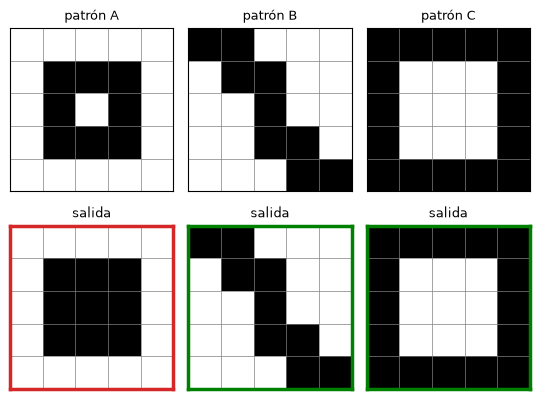

In [18]:
forma5 = (5, 5)
nombres5 = list(FIG5)
X5 = np.array([p.ravel() for p in FIG5.values()])
W5 = entrenar_hebb(X5)
print("W simétrica:", np.allclose(W5, W5.T), "| diagonal nula:", np.allclose(np.diag(W5), 0))

M5 = X5 @ X5.T / 25
print("Superposiciones m entre patrones:")
display(pd.DataFrame(M5, index=nombres5, columns=nombres5).round(2))

filas, salidas5 = [], []
for k, x in zip(nombres5, X5):
    sf, _ = recuperar(W5, x, rng); salidas5.append(sf)
    nombre = next((n for n, y in zip(nombres5, X5) if np.array_equal(sf, y)), None) or \
             next((f"−{n}" for n, y in zip(nombres5, X5) if np.array_equal(sf, -y)), "espurio")
    filas.append({"patrón": k, "¿estable?": es_estable(W5, x), "píxeles inestables": int((x * (W5 @ x) < -1e-12).sum()),
                  "E(patrón)": round(energia(W5, x), 2), "salida desde el patrón": nombre})
display(pd.DataFrame(filas).set_index("patrón"))

fig, axs = plt.subplots(2, 3, figsize=(5.5, 4.2))
for j, (k, x, sf) in enumerate(zip(nombres5, X5, salidas5)):
    dibujar(axs[0, j], x, forma5, f"patrón {k}")
    dibujar(axs[1, j], sf, forma5, "salida", ok=np.array_equal(sf, x))
plt.tight_layout(); plt.show()

*Los patrones $B$ y $C$ son estables, pero $A$ no, hay un píxel (el central) cuyo campo local lo contradice, y al dejar evolucionar la red desde $A$ se llega a $-C$.*

In [19]:
print("Almacenando solo pares de patrones:")
for (i, a), (j, b) in itertools.combinations(list(enumerate(nombres5)), 2):
    Wp = entrenar_hebb(X5[[i, j]])
    print(f"  {{{a},{b}}}: {a} estable = {es_estable(Wp, X5[i])}, {b} estable = {es_estable(Wp, X5[j])}")

Almacenando solo pares de patrones:
  {A,B}: A estable = True, B estable = True
  {A,C}: A estable = True, C estable = True
  {B,C}: B estable = True, C estable = True


*La causa es la correlación entre patrones. $A$ difiere de $-C$ en un solo píxel (superposición $m_{AC}=-0.92$). Para la red hebbiana $A$ y $-C$ son casi la misma memoria. No es un problema de cantidad ($M/N=3/25=0.12<0.138$), de a pares, los tres patrones sí son estables, y el tercero desestabiliza el píxel central de $A$. La energía decrece en cada cambio de neurona, como asegura la teoría.*

### 2. Memoria asociativa con los dígitos de la Figura 6

Son 10 dígitos de $7\times5$ píxeles, es decir $N=35$ neuronas. Se almacenan los 10 con la regla de Hebb y se ve qué devuelve la red cuando se parte de cada dígito limpio.

Superposición media entre dígitos distintos: 0.21 (aleatorios: ≈0 ± 0.17); máxima: 0.89
Par más parecido: 3 y 8 (difieren en 2 píxeles de 35)
Dígitos estables: 0 de 10
Píxeles inestables por dígito: [9, 5, 5, 1, 5, 9, 6, 4, 1, 5]
Estados finales distintos desde los 10 dígitos: 2


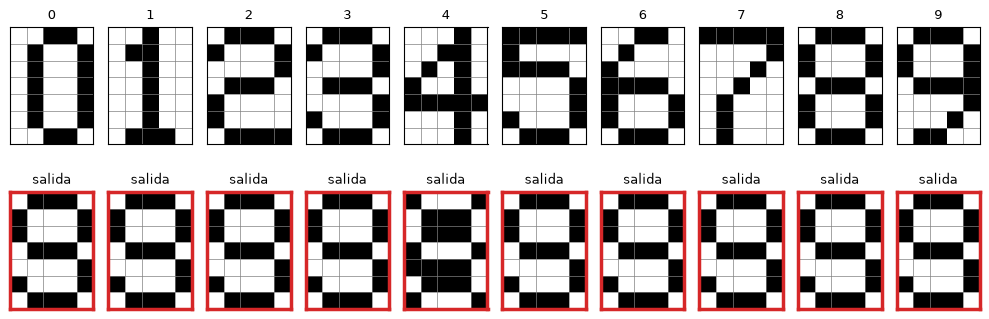

In [20]:
forma6 = (7, 5)
X6 = np.array([DIGITOS[d].ravel() for d in range(10)])
W6 = entrenar_hebb(X6)
M6 = X6 @ X6.T / 35
fuera = M6[np.triu_indices(10, 1)]
print(f"Superposición media entre dígitos distintos: {fuera.mean():.2f} (aleatorios: ≈0 ± {1/np.sqrt(35):.2f}); máxima: {fuera.max():.2f}")
i, j = np.unravel_index(np.argmax(np.where(np.eye(10) > 0, -1, M6)), M6.shape)
print(f"Par más parecido: {i} y {j} (difieren en {int((X6[i] != X6[j]).sum())} píxeles de 35)")

estables = [es_estable(W6, x) for x in X6]
salidas = [recuperar(W6, x, rng)[0] for x in X6]
print("Dígitos estables:", sum(estables), "de 10")
print("Píxeles inestables por dígito:", [int((x * (W6 @ x) < -1e-12).sum()) for x in X6])
print("Estados finales distintos desde los 10 dígitos:", len({tuple(s.astype(int)) for s in salidas}))

fig, axs = plt.subplots(2, 10, figsize=(10, 3.6))
for d in range(10):
    dibujar(axs[0, d], X6[d], forma6, str(d))
    dibujar(axs[1, d], salidas[d], forma6, "salida", ok=np.array_equal(salidas[d], X6[d]))
plt.tight_layout(); plt.show()

*Con los 10 dígitos la regla de Hebb falla compeltamente, ningún dígito es estable y la red converge a estados espurios. Hay dos causas. Una es la carga, $M/N=10/35\approx0.29$, el doble del límite $0.138$. La otra es que los dígitos están muy correlacionados (superposición media $0.21$), por ejemplo, el 3 y el 8 difieren en solo 2 píxeles.*

Lo que podemos hacer es ver cuántos dígitos puede almacenar. Para cada tamaño $m$ se prueban todos los subconjuntos posibles de $m$ dígitos (en total $2^{10}-1$) y se registra cuántos tienen todos sus dígitos estables.

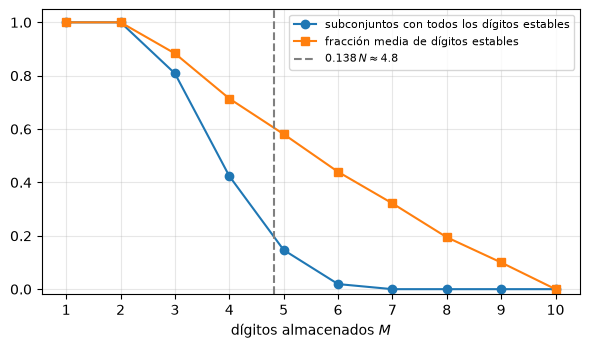

,1,2,3,4,5,6,7,8,9,10
subconjuntos,10,45,120,210,252,210,120,45,10,1
con todos estables,10,45,97,89,37,4,0,0,0,0


Subconjuntos de 6 dígitos totalmente estables: [(0, 1, 2, 4, 5, 7), (0, 1, 4, 5, 6, 7), (0, 2, 4, 5, 6, 7), (1, 2, 4, 5, 6, 7)]


In [21]:
ms = np.arange(1, 11)
total, buenos, frac_est = {}, {}, {}
for m in ms:
    subs = list(itertools.combinations(range(10), m))
    est = [[es_estable(entrenar_hebb(X6[list(s)]), X6[d]) for d in s] for s in subs]
    total[m] = len(subs)
    buenos[m] = [s for s, e in zip(subs, est) if all(e)]
    frac_est[m] = np.mean([np.mean(e) for e in est])

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(ms, [len(buenos[m]) / total[m] for m in ms], "o-", label="subconjuntos con todos los dígitos estables")
ax.plot(ms, [frac_est[m] for m in ms], "s-", label="fracción media de dígitos estables")
ax.axvline(0.138 * 35, color="gray", ls="--", label="$0.138\\,N\\approx4.8$")
ax.set(xlabel="dígitos almacenados $M$", ylim=(-0.02, 1.05)); ax.set_xticks(ms); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

display(pd.DataFrame({"subconjuntos": total, "con todos estables": {m: len(buenos[m]) for m in ms}}).T)
print("Subconjuntos de 6 dígitos totalmente estables:", buenos[6])

*Con 1 o 2 dígitos siempre hay estabilidad. Luego, a medida que crece la cantidad de dígitos, la estabilidad cae constantemente, llegando a un máximo posible de 6 dígitos. Para 7 o más, la red no es capaz de mantener estabilidad en ningún dígito.*

*Los 4 conjuntos máximos siempre contienen el 4, el 5 y el 7, pero nunca incluyen el 3, 8 ni 9, que son los más parecidos entre sí. Entonces 6 es la capacidad en el mejor caso, con combinaciones muy particulares de dígitos. Para un subconjunto cualquiera solo se garantizan 2 dígitos (con 3 ya fallan 23 de 120) y con 5 dígitos funciona solo el 15 % de los subconjuntos, en línea con el límite teórico $0.138N\approx4.8$. La capacidad depende de cuáles patrones se guardan, no solo de cuántos.*

Entonces, se usa como memoria uno de estos conjuntos máximos y se prueba como memoria asociativa. Se parte de cada dígito con 4 píxeles invertidos al azar y se mira si la red reconstruye el original.

Dígitos almacenados: [0, 1, 2, 4, 5, 7] | todos estables: True


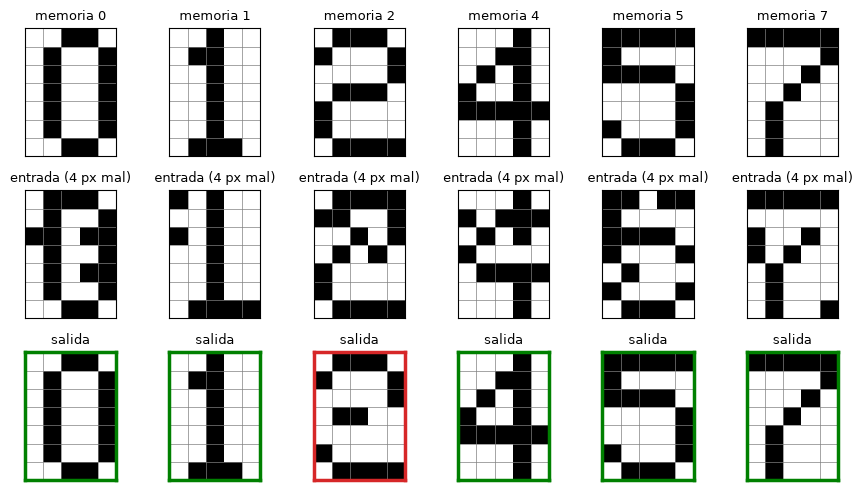

Recuperación correcta con 4 píxeles invertidos (%, 500 corridas por dígito): {0: 94, 1: 92, 2: 55, 4: 91, 5: 94, 7: 80}


In [ ]:
MEM = list(buenos[6][0])
W_mem = entrenar_hebb(X6[MEM])
print("Dígitos almacenados:", MEM, "| todos estables:", all(es_estable(W_mem, X6[d]) for d in MEM))

fig, axs = plt.subplots(3, len(MEM), figsize=(1.5 * len(MEM), 5.0))
for j, d in enumerate(MEM):
    s0 = X6[d].astype(float).copy(); s0[rng.choice(35, 4, replace=False)] *= -1
    sf, _ = recuperar(W_mem, s0, rng)
    dibujar(axs[0, j], X6[d], forma6, f"memoria {d}")
    dibujar(axs[1, j], s0, forma6, "entrada (4 px mal)")
    dibujar(axs[2, j], sf, forma6, "salida", ok=np.array_equal(sf, X6[d]))
plt.tight_layout(); plt.show()


T = 500
tasa = {}
for d in MEM:
    ok = 0
    for _ in range(T):
        s0 = X6[d].astype(float).copy(); s0[rng.choice(35, 4, replace=False)] *= -1
        ok += np.array_equal(recuperar(W_mem, s0, rng)[0], X6[d])
    tasa[d] = round(100 * ok / T)
print(f"Recuperación correcta con 4 píxeles invertidos (%, {T} corridas por dígito):", tasa)

*La red funciona como memoria direccionable por contenido, no se le indica qué dígito es y, a partir de una imagen degradada, reconstruye la memoria más cercana. Pero la recuperación no está garantizada, ni siquiera con solo 4 píxeles mal, depende de cuáles píxeles se invirtieron y del orden de actualización. Para entender mejor la tasa de recuperación de cada dígito, se hicieron 500 corridas con diferentes inicializaciones de los 4 píxeles ruidosos. Des esta forma las tasas fueron 94 %, 90 %, 57 %, 89 %, 94 % y 82 % para los dígitos 0, 1, 2, 4, 5 y 7, respectivamente. El 2 es el más difícil y los demás se recuperan entre el 82 % y el 94 % de las veces.*

### 3. Recuperación a partir de dígitos ruidosos

Ahora, para entender mejor cómo se comporta frente a ruido, se invierte cada píxel de cada dígito con probabilidad $p=0.1,\,0.2,\,0.5$ y se deja evolucionar la red. Para cada dígito y cada $p$ se hacen 200 corridas, y se clasifica la salida en: **correcta** (el dígito original), **otro dígito** almacenado, **invertida** (el negativo de un dígito almacenado) o **espuria** (cualquier otra cosa). Se usa la misma memoria de 6 dígitos que se usó previamente.

In [26]:
def clasificar(sf, d, dig):
    if np.array_equal(sf, X6[d]): return "correcta"
    if any(np.array_equal(sf, X6[k]) for k in dig): return "otro dígito"
    if any(np.array_equal(sf, -X6[k]) for k in dig): return "invertida"
    return "espuria"


def experimento(W, dig, p, T=200):
    cuentas = {c: np.zeros(len(dig)) for c in ["correcta", "otro dígito", "invertida", "espuria"]}
    for n, d in enumerate(dig):
        for _ in range(T):
            sf, _ = recuperar(W, ruido(X6[d], p, rng), rng)
            cuentas[clasificar(sf, d, dig)][n] += 1
    return pd.DataFrame(cuentas, index=dig) / T


memorias = {"Hebb, 6 dígitos": (W_mem, MEM)}
ps = [0.1, 0.2, 0.5]
res = {(n, p): experimento(W, dig, p) for n, (W, dig) in memorias.items() for p in ps}

tabla = pd.DataFrame({k: v.mean() for k, v in res.items()}).T * 100
tabla.index.names = ["memoria", "p"]
print("Porcentaje de salidas de cada tipo (promedio sobre los dígitos de la memoria):")
display(tabla.round(1))
print("Recuperación correcta por dígito (%), Hebb con 6 dígitos:")
display((100 * pd.DataFrame({p: res[("Hebb, 6 dígitos", p)]["correcta"] for p in ps})).round(0).astype(int).T.rename_axis("p"))

Porcentaje de salidas de cada tipo (promedio sobre los dígitos de la memoria):


correcta  otro dígito  invertida  espuria
memoria         p                                             
Hebb, 6 dígitos 0.1      84.8          0.1        0.0     15.2
                0.2      66.3          1.0        0.5     32.2
                0.5       3.2         14.2       20.7     61.9

Recuperación correcta por dígito (%), Hebb con 6 dígitos:


,0,1,2,4,5,7
p,,,,,,
0.1,94,94,54,90,92,84
0.2,77,76,42,69,74,60
0.5,4,3,2,4,4,2


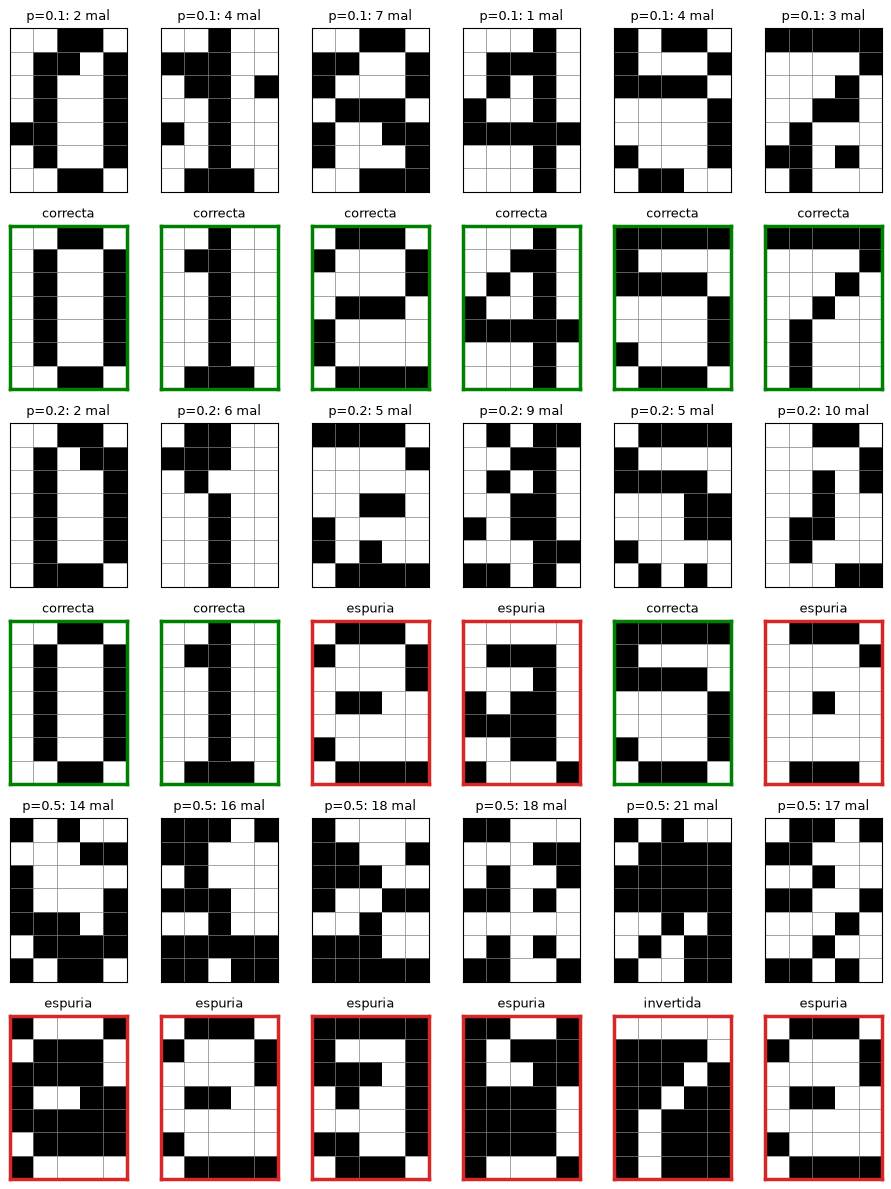

In [27]:
mostrar = MEM
fig, axs = plt.subplots(2 * len(ps), len(mostrar), figsize=(1.55 * len(mostrar), 2.0 * 2 * len(ps)))
for r, p in enumerate(ps):
    for c, d in enumerate(mostrar):
        s0 = ruido(X6[d], p, rng); sf, _ = recuperar(W_mem, s0, rng)
        cat = clasificar(sf, d, MEM)
        dibujar(axs[2 * r, c], s0, forma6, f"p={p}: {int((s0 != X6[d]).sum())} mal")
        dibujar(axs[2 * r + 1, c], sf, forma6, cat, ok=(cat == "correcta"))
plt.tight_layout(); plt.show()

*Con la memoria de 6 dígitos la red devuelve el dígito correcto en el **85 %** de las corridas con $p=0.1$, en el **62 %** con $p=0.2$ y en el **3 %** con $p=0.5$. Cuando falla casi siempre es un estado espurio, apenas confunde un dígito con otro. Los dígitos más parecidos a otros son los más difíciles. Con $p=0.5$ la entrada es un estado al azar que no contiene información del dígito, la salida no depende de cuál era el original y cae en uno de los estados espurios.*

### Conclusiones

1. La red de Hopfield con regla de Hebb se entrena en un solo paso y su dinámica asincrónica disminuye la energía en cada cambio, así que siempre converge a un estado estable. Cada patrón almacenado viene acompañado de su inverso.
2. **Figura 5:** Se almacenaron solo 2 de los 3 patrones, $A$ no es estable porque es casi idéntico a $-C$ (1 píxel de diferencia) y la red lo lleva a $-C$. Aunque $M/N=0.12<0.138$, el límite de capacidad vale para patrones no correlacionados, con patrones correlacionados el ruido cruzado desestabiliza antes.
3. **Figura 6:** Con los 10 dígitos ninguno es estable, por la carga ($M/N\approx0.29$) y sobre todo por la correlación entre dígitos. El máximo almacenable con Hebb en el mejor caso es de 6 dígitos.
4. Con la memoria de 6 dígitos se recupera el dígito correcto en el 85 % ($p=0.1$), 62 % ($p=0.2$) y 3 % ($p=0.5$) de las corridas. Con $p=0.5$ la entrada no contiene información del dígito. Los fallos son sobre todo estados espurios.
5. Con los 10 dígitos la recuperación es 0 % para cualquier nivel de ruido. La limitación es de la regla de Hebb frente a patrones correlacionados, no de la arquitectura de Hopfield. Para usar los 10 dígitos habría que usar otra regla de aprendizaje (por ejemplo, la pseudoinversa) o patrones menos correlacionados.